In [31]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [32]:
df = pd.read_csv("./datasets/loan_approval_data.csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [33]:

df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [34]:
#handle missing value
#for numerical can be filled with mean
#for categorical data mode (most frequent) can be used

categorical_cols = df.select_dtypes(include=["object"]).columns
numerical_cols = df.select_dtypes(include=["float64", "int64"]).columns

In [35]:
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [36]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy="mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

In [37]:
df.isnull().sum()

Applicant_ID           0
Applicant_Income       0
Coapplicant_Income     0
Employment_Status     50
Age                    0
Marital_Status        50
Dependents             0
Credit_Score           0
Existing_Loans         0
DTI_Ratio              0
Savings                0
Collateral_Value       0
Loan_Amount            0
Loan_Term              0
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [38]:
num_imp = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = num_imp.fit_transform(df[categorical_cols])

In [39]:
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

Text(0.5, 1.0, 'Loan approved or not ?')

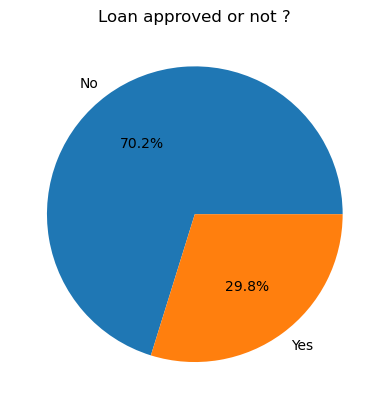

In [40]:
#EDA 
#how balanced classes are?

classes_count  = df["Loan_Approved"].value_counts()
plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Loan approved or not ?")

[Text(0, 0, '621'), Text(0, 0, '379')]

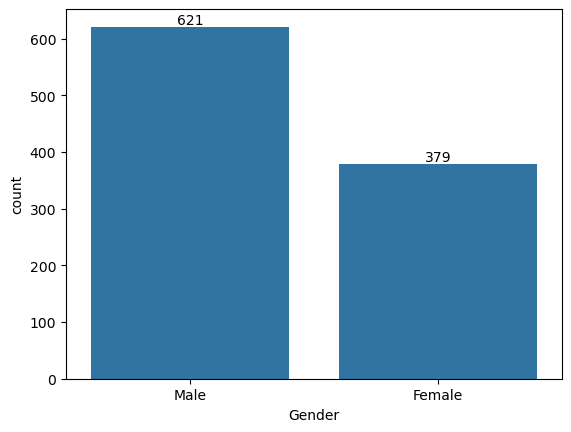

In [41]:
#analyse categories 
gender_cnt = df["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

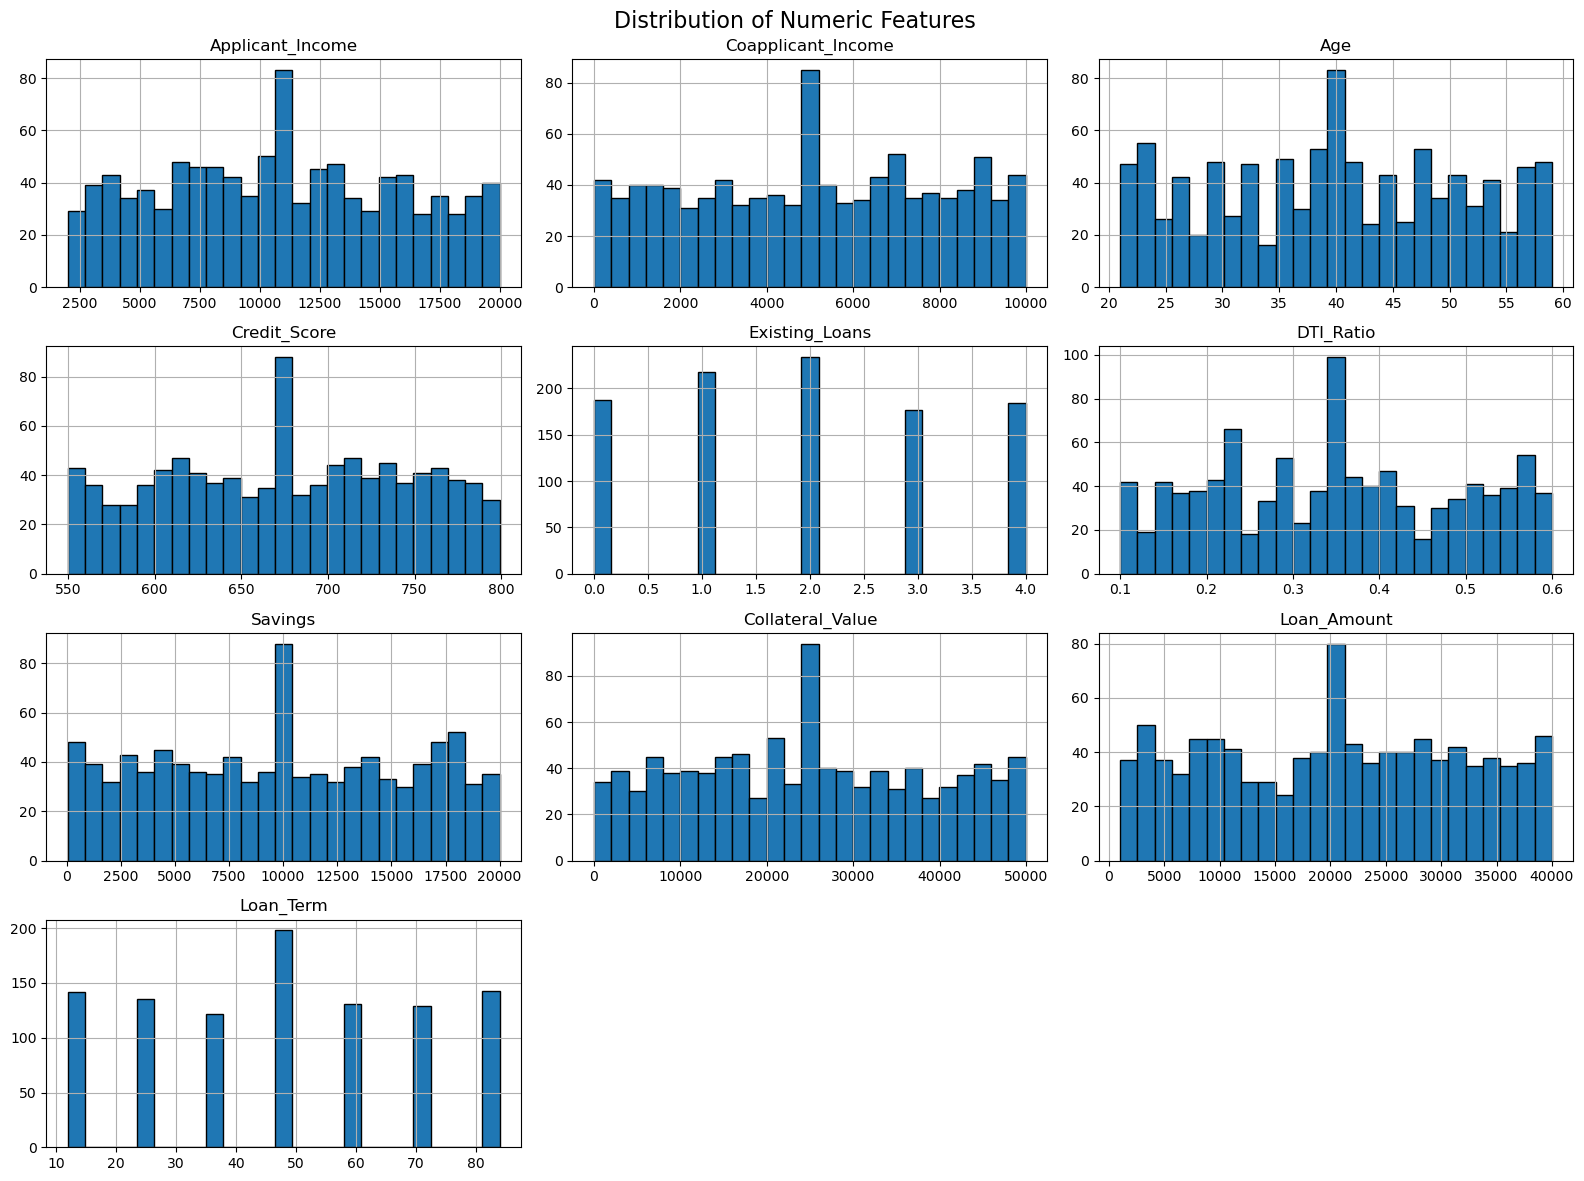

In [42]:
numeric_cols = [
    "Applicant_Income",
    "Coapplicant_Income",
    "Age",
    "Credit_Score",
    "Existing_Loans",
    "DTI_Ratio",
    "Savings",
    "Collateral_Value",
    "Loan_Amount",
    "Loan_Term"
]

# Histograms
df[numeric_cols].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Features", fontsize=16)
plt.tight_layout()
plt.show()

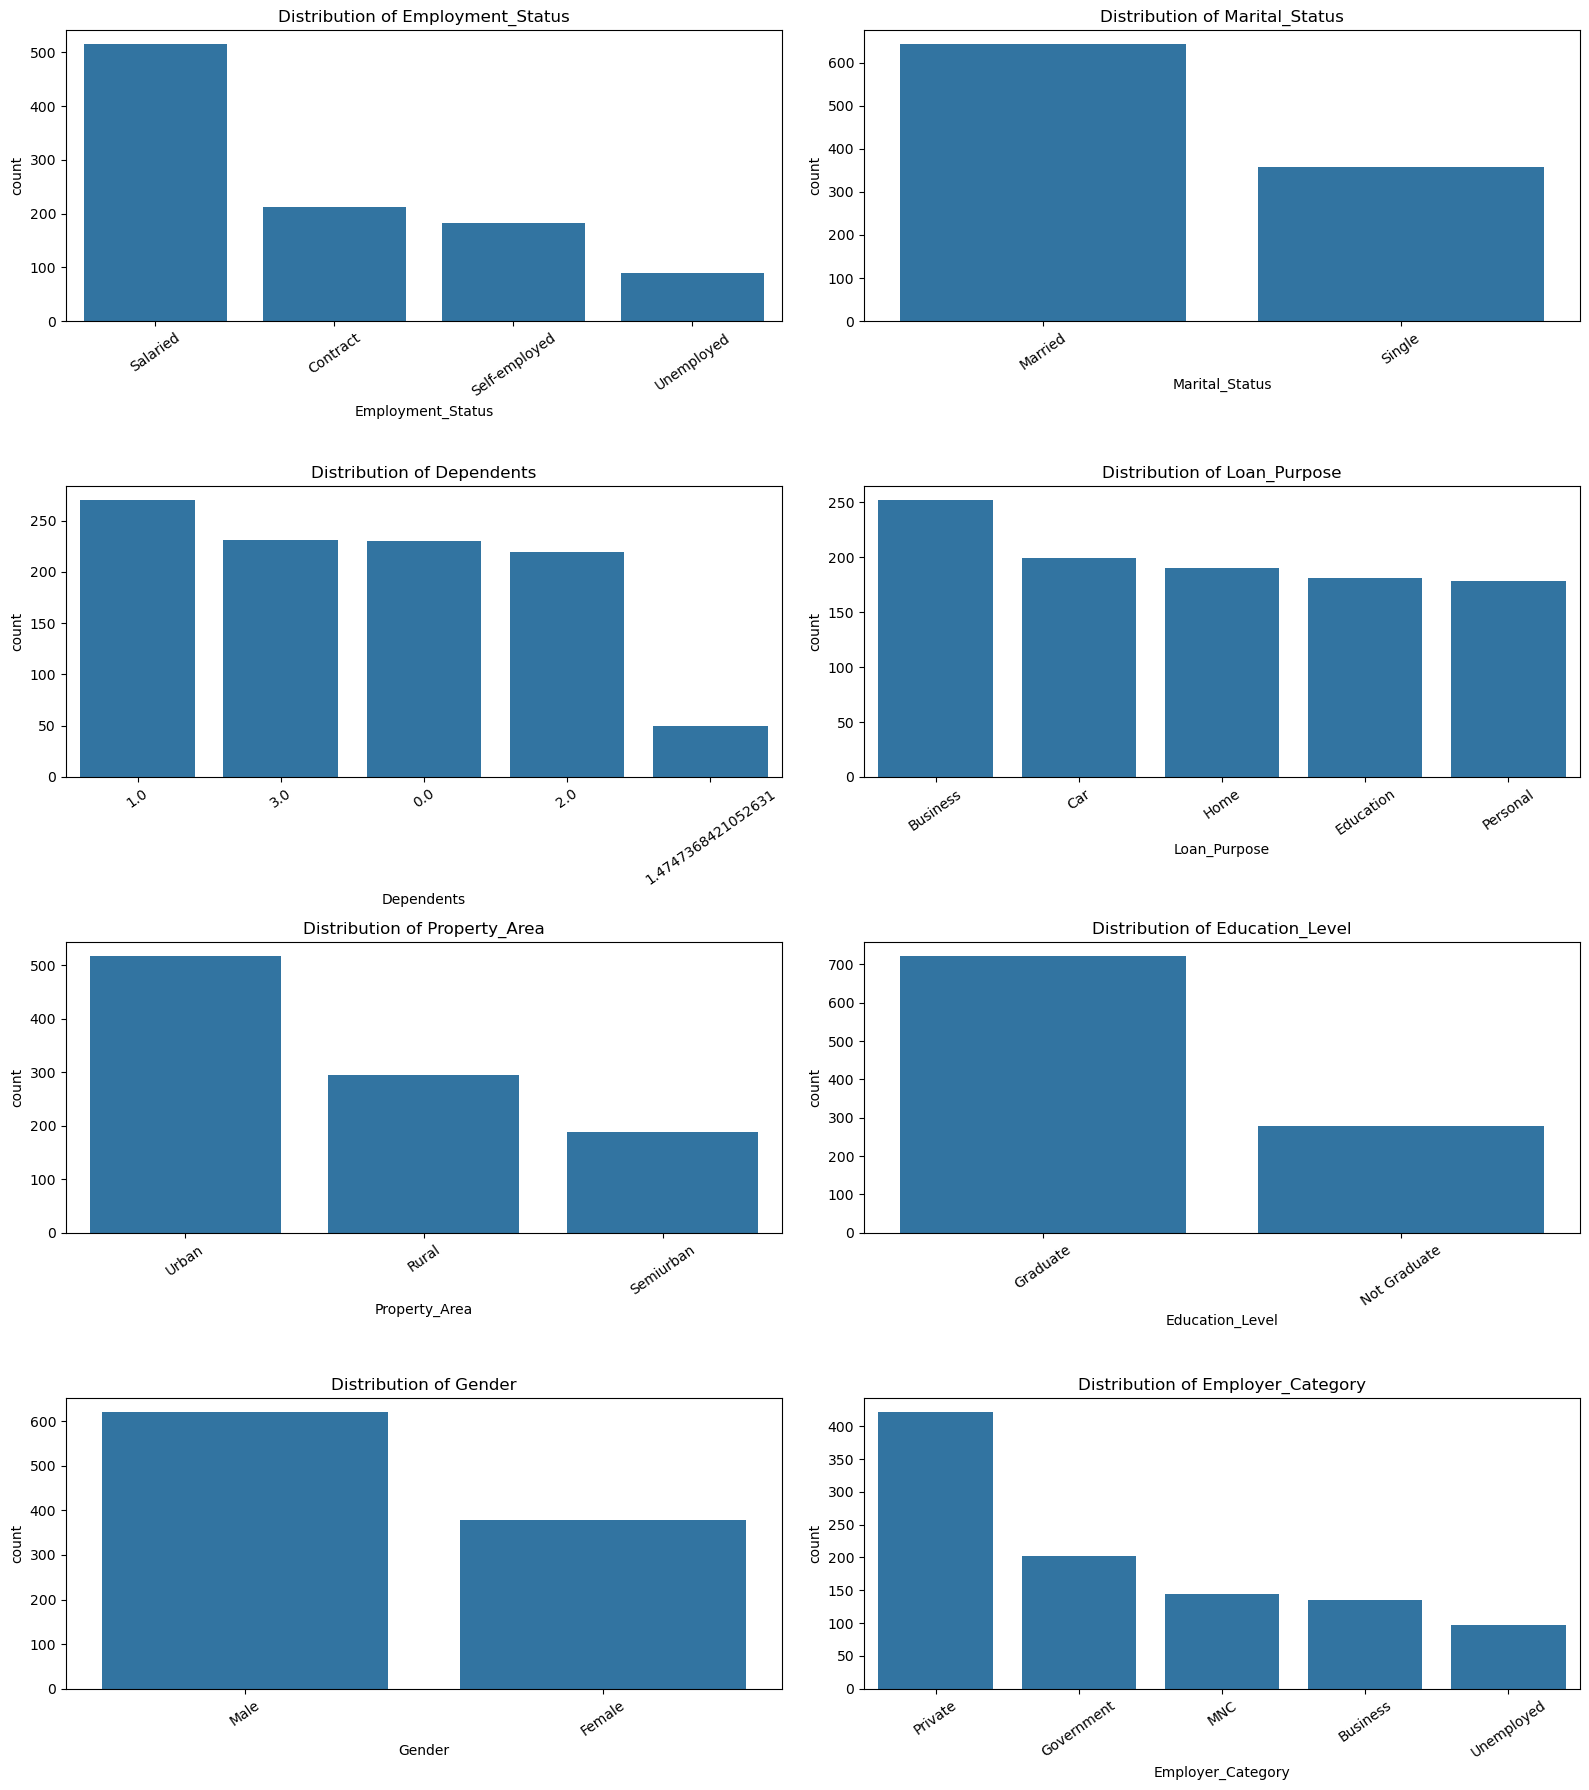

In [47]:
categorical_cols = [
    "Employment_Status",
    "Marital_Status",
    "Dependents",
    "Loan_Purpose",
    "Property_Area",
    "Education_Level",
    "Gender",
    "Employer_Category"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

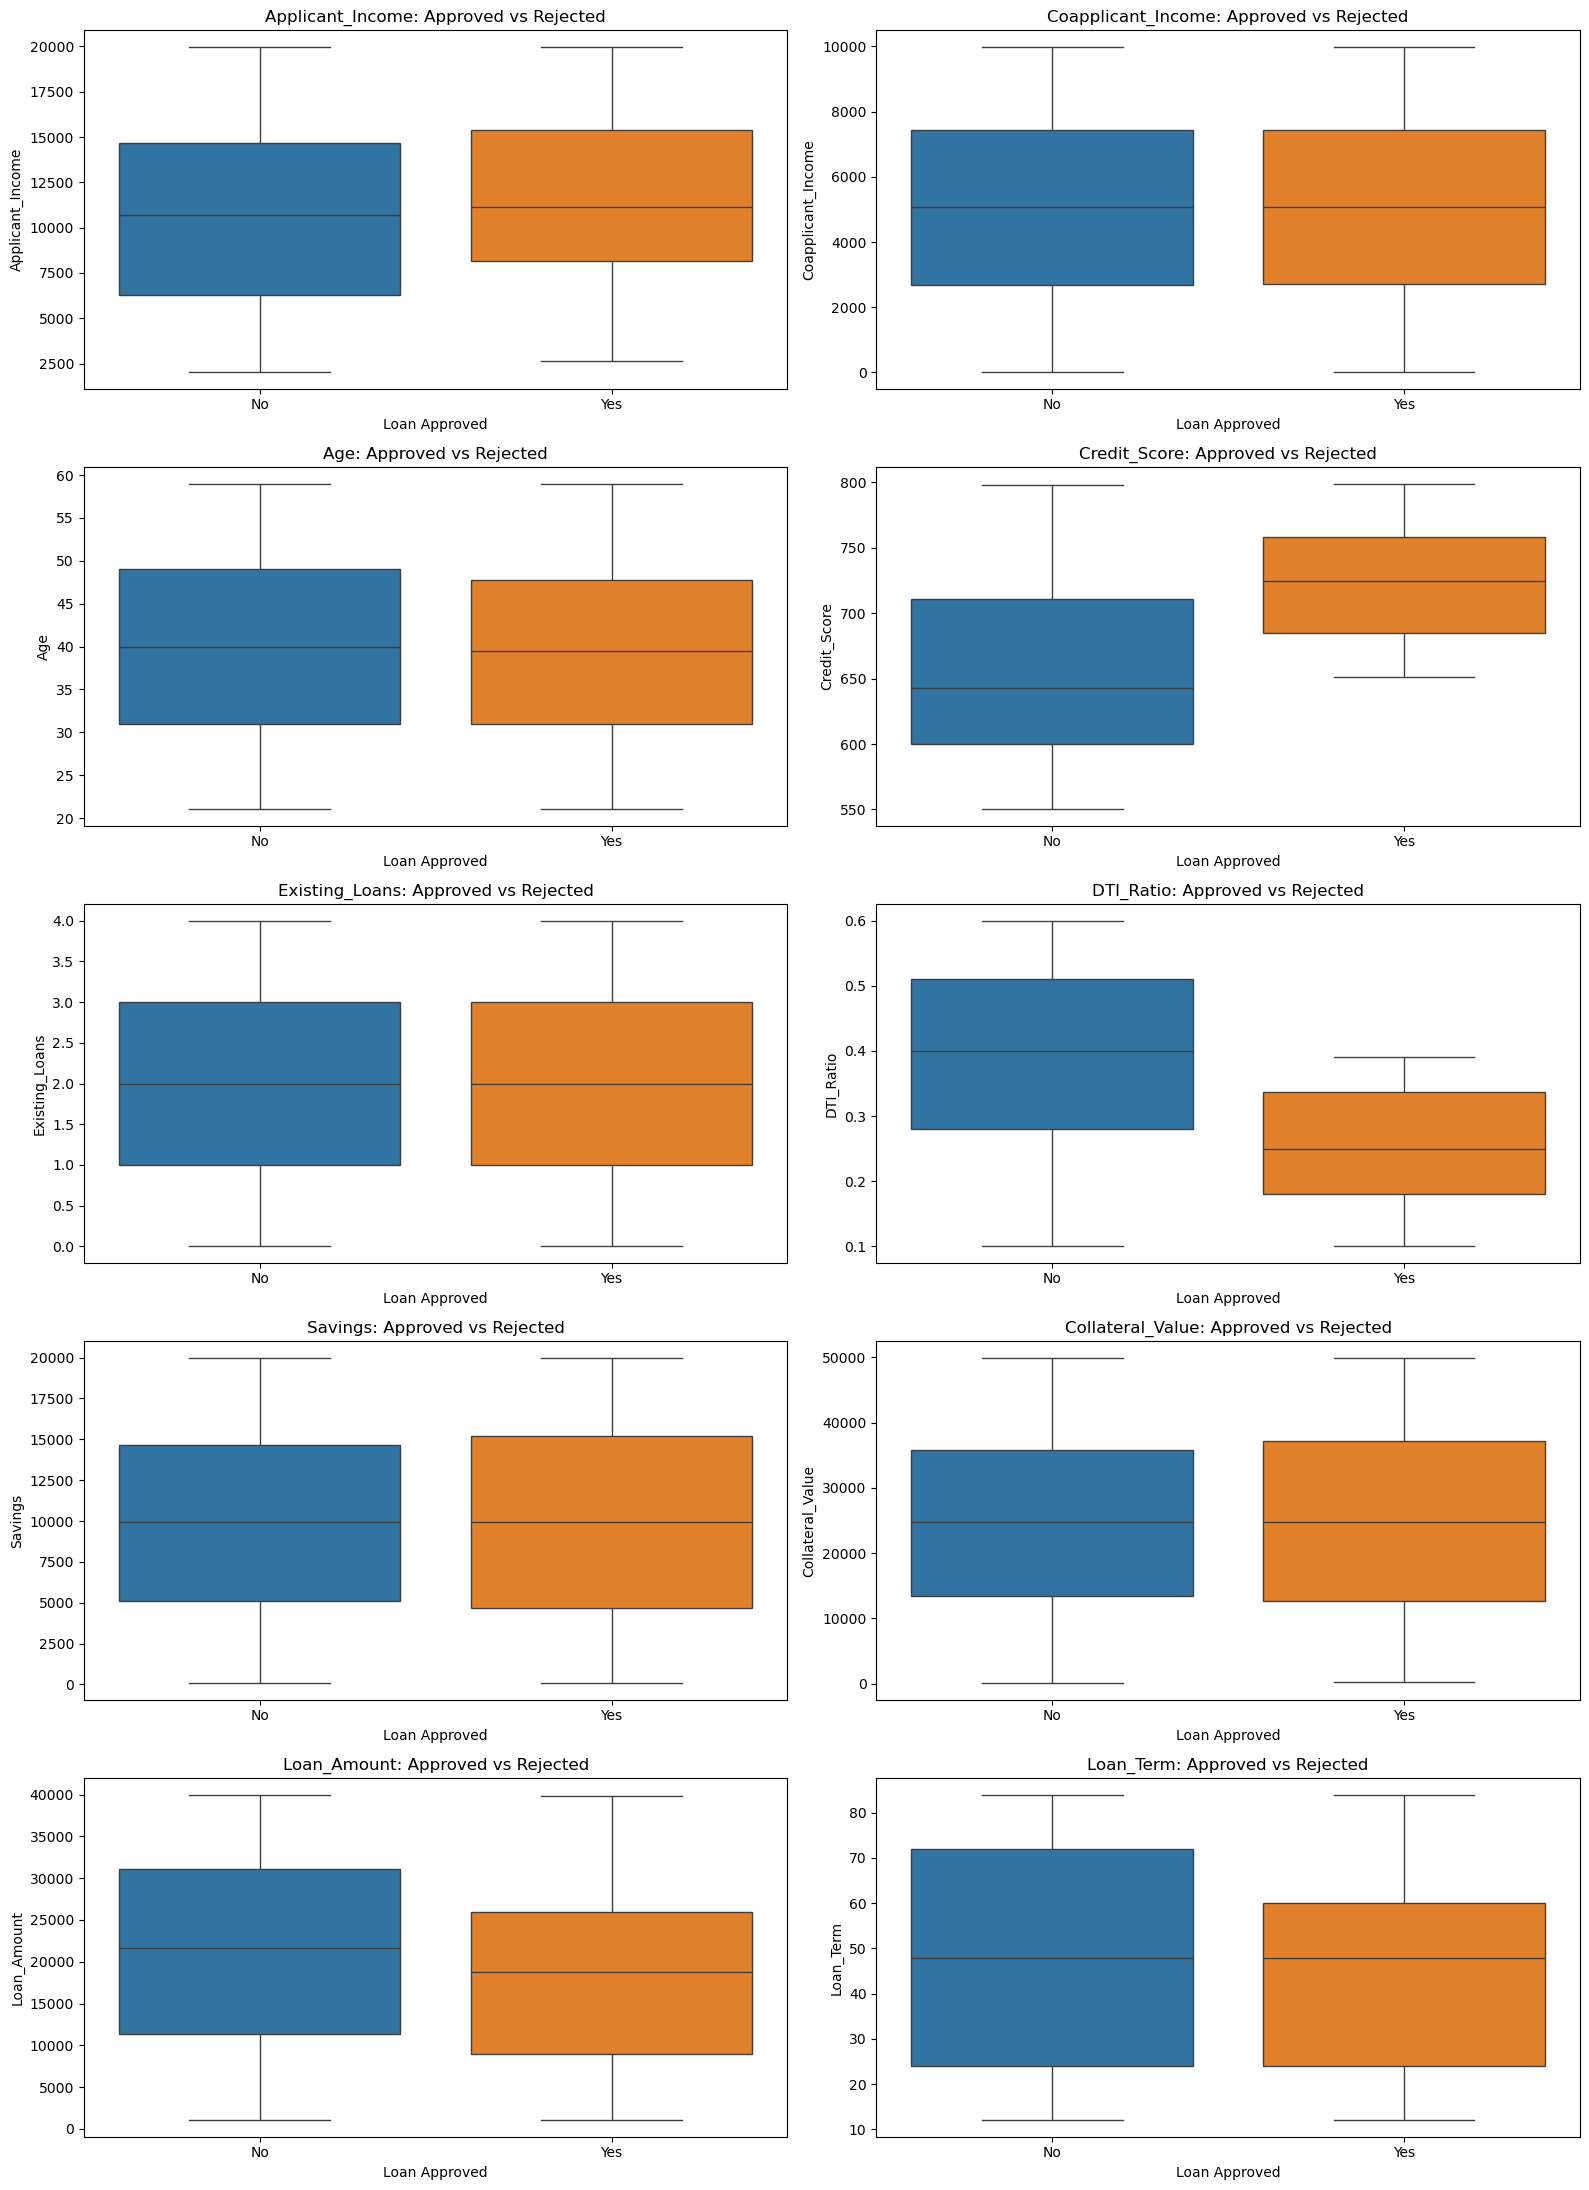

In [48]:
features = [
    "Applicant_Income",
    "Coapplicant_Income",
    "Age",
    "Credit_Score",
    "Existing_Loans",
    "DTI_Ratio",
    "Savings",
    "Collateral_Value",
    "Loan_Amount",
    "Loan_Term"
]

fig, axes = plt.subplots(5, 2, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        data=df,
        x="Loan_Approved",
        y=col,
        hue="Loan_Approved",
        ax=axes[i],
        order=["No", "Yes"],
        hue_order=["No", "Yes"],
        legend=False
    )

    axes[i].set_title(f"{col}: Approved vs Rejected")
    axes[i].set_xlabel("Loan Approved")
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

<Axes: xlabel='Credit_Score', ylabel='Count'>

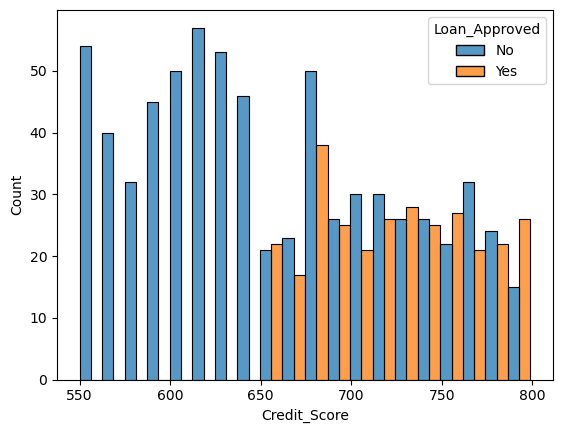

In [49]:
#credit score with loan Approval

sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)


In [46]:
#Remove Applicant id
df = df.drop("Applicant_ID", axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    1000 non-null   float64
 1   Coapplicant_Income  1000 non-null   float64
 2   Employment_Status   1000 non-null   object 
 3   Age                 1000 non-null   float64
 4   Marital_Status      1000 non-null   object 
 5   Dependents          1000 non-null   float64
 6   Credit_Score        1000 non-null   float64
 7   Existing_Loans      1000 non-null   float64
 8   DTI_Ratio           1000 non-null   float64
 9   Savings             1000 non-null   float64
 10  Collateral_Value    1000 non-null   float64
 11  Loan_Amount         1000 non-null   float64
 12  Loan_Term           1000 non-null   float64
 13  Loan_Purpose        1000 non-null   object 
 14  Property_Area       1000 non-null   object 
 15  Education_Level     1000 non-null   object 
 16  Gender 

In [29]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
#label encoder assigns a value to each category(ordinal data: education level , diffcult label)
#one hot enc: creates new col based upon the category(nominal data: every cat is imp)

In [50]:
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])

In [55]:
cols  = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]

one_ht_enc = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded_val = one_ht_enc.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded_val, columns=one_ht_enc.get_feature_names_out(cols),index=df.index)

df = pd.concat([df.drop(columns = cols), encoded_df], axis=1)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

In [61]:
#corelation heatmap
nums_cols = df.select_dtypes(include="number")
corr_matrix = nums_cols.corr()

corr_matrix["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

<Axes: >

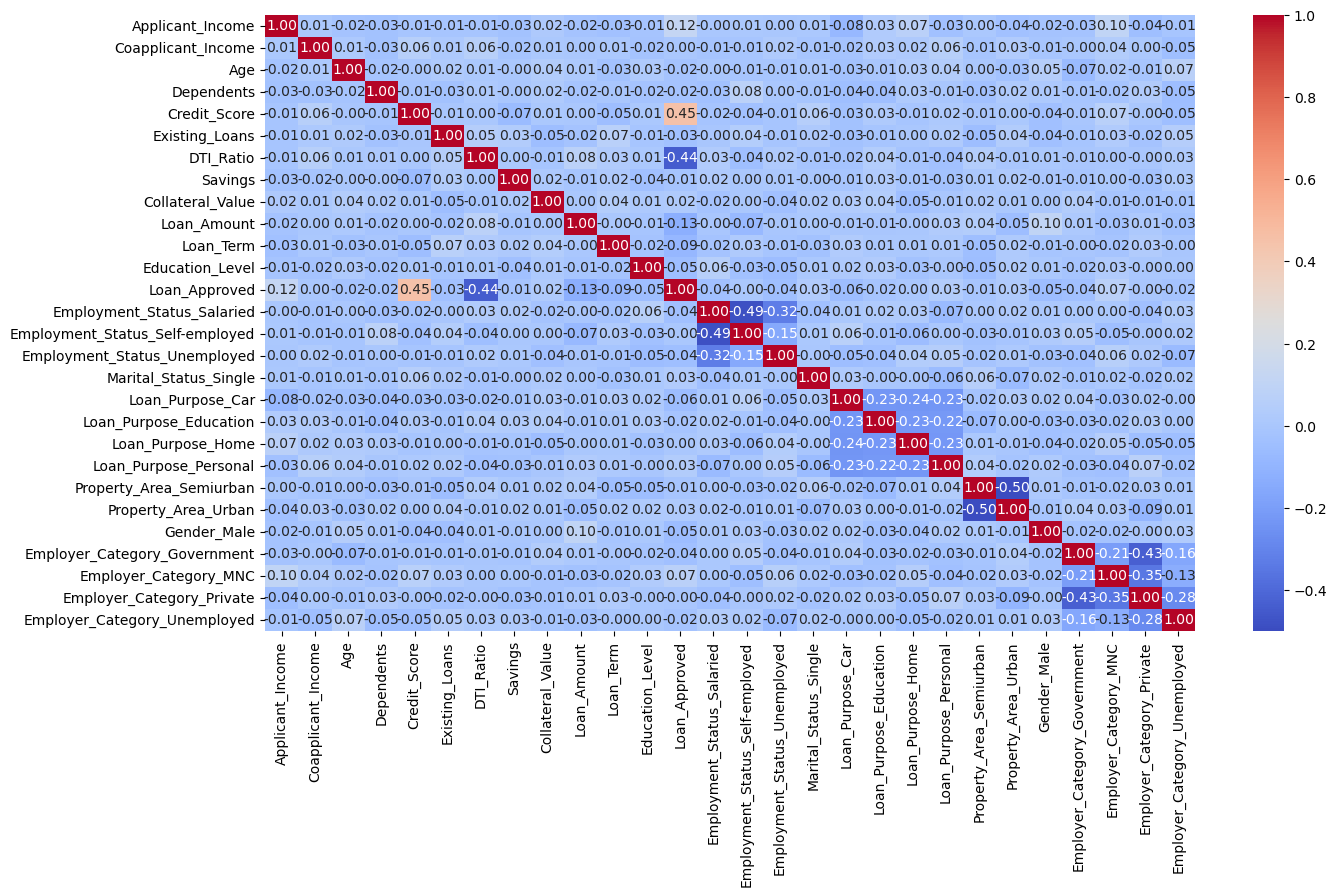

In [63]:
plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [89]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]


In [90]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [94]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [98]:
# Logistic Reg
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, accuracy_score, confusion_matrix, f1_score


log_model = LogisticRegression()

log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)


print("Logistic Regression Evaluation")
print("-" * 35)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Evaluation
-----------------------------------
Accuracy : 0.865
Precision: 0.7833333333333333
Recall   : 0.7704918032786885
F1 Score : 0.7768595041322314

Confusion Matrix:
[[126  13]
 [ 14  47]]


In [102]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (recall_score, precision_score, accuracy_score, confusion_matrix, f1_score)

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_test_scaled)

print("KNN Evaluation")
print("-" * 35)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

KNN Evaluation
-----------------------------------
Accuracy : 0.76
Precision: 0.6274509803921569
Recall   : 0.5245901639344263
F1 Score : 0.5714285714285714

Confusion Matrix:
[[120  19]
 [ 29  32]]


In [103]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import ( recall_score, precision_score, accuracy_score, confusion_matrix, f1_score, classification_report)

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_test_scaled)

print("Naive Bayes Evaluation")
print("-" * 35)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Naive Bayes Evaluation
-----------------------------------
Accuracy : 0.865
Precision: 0.8035714285714286
Recall   : 0.7377049180327869
F1 Score : 0.7692307692307693

Confusion Matrix:
[[128  11]
 [ 16  45]]


In [108]:
df["DTI_Ratio_sq"] = df["DTI_Ratio"] ** 2
df["Credit_Score_sq"] = df["Credit_Score"] ** 2

# df["Applicant_income_log"] = np.log1p(df["Applicant_Income"])

X = df.drop(columns=["Loan_Approved", "DTI_Ratio_sq", "Credit_Score_sq"])
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

nb_scaled_model = GaussianNB()

nb_scaled_model.fit(X_train_scaled, y_train)

y_pred = nb_scaled_model.predict(X_test_scaled)

print("Scaleld Naive Bayes Evaluation")
print("-" * 35)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Scaleld Naive Bayes Evaluation
-----------------------------------
Accuracy : 0.86
Precision: 0.8367346938775511
Recall   : 0.6721311475409836
F1 Score : 0.7454545454545455

Confusion Matrix:
[[131   8]
 [ 20  41]]
